In [1]:
%pip install opencv-python

Note: you may need to restart the kernel to use updated packages.


Enhanced image saved as: enhanced_image.jpg


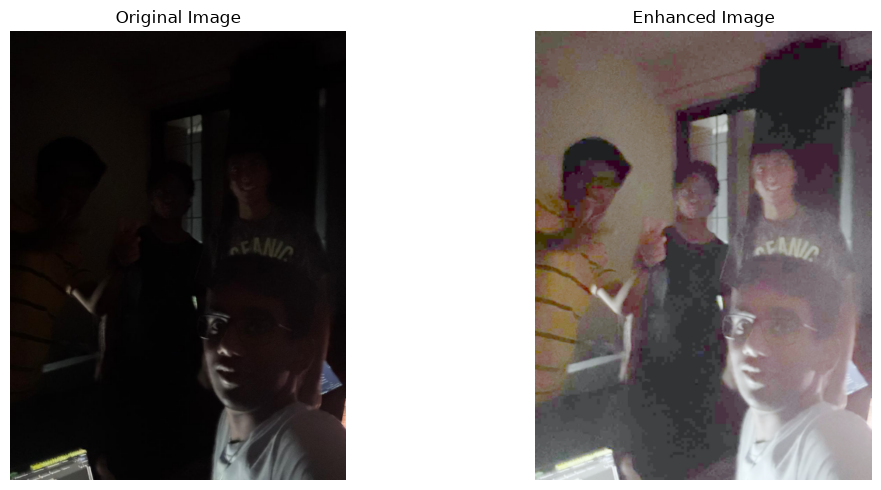

In [10]:
import numpy as np
import cv2
import matplotlib.pyplot as plt


# ============================================================
# 1. LOAD IMAGE
# ============================================================

input_path = "input4.jpg"
output_path = "enhanced_image.jpg"

img = cv2.imread(input_path)

if img is None:
    raise FileNotFoundError(f"Could not find image: {input_path}")

# OpenCV loads images as BGR, convert to RGB
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Convert to floating point
img_float = img_rgb.astype(np.float64)


# ============================================================
# 2. GAUSSIAN FILTER
# ============================================================

# 5x5 Gaussian kernel used in the paper
gaussian_kernel = np.array([
    [1,  4,  7,  4, 1],
    [4, 16, 26, 16, 4],
    [7, 26, 41, 26, 7],
    [4, 16, 26, 16, 4],
    [1,  4,  7,  4, 1]
], dtype=np.float64)

# Normalize kernel
gaussian_kernel /= np.sum(gaussian_kernel)

# Apply Gaussian convolution independently to R, G and B
gaussian_img = np.zeros_like(img_float)

for channel in range(3):
    gaussian_img[:, :, channel] = cv2.filter2D(
        img_float[:, :, channel],
        -1,
        gaussian_kernel
    )


# ============================================================
# 3. LOGARITHMIC TRANSFORMATION
# ============================================================

# Constant from the paper
K = 1.5

# GL(x,y) = K * log2(1 + G(x,y))
log_img = K * np.log2(1.0 + gaussian_img)


# ============================================================
# 4. MIN-MAX NORMALIZATION / GAIN-OFFSET CORRECTION
# ============================================================

enhanced_img = np.zeros_like(log_img)

for channel in range(3):

    channel_data = log_img[:, :, channel]

    minimum = np.min(channel_data)
    maximum = np.max(channel_data)

    # Avoid division by zero for a completely uniform channel
    if maximum == minimum:
        enhanced_img[:, :, channel] = 0
    else:
        enhanced_img[:, :, channel] = (
            255.0 *
            (channel_data - minimum) /
            (maximum - minimum)
        )


# ============================================================
# 5. CONVERT TO 8-BIT IMAGE
# ============================================================

enhanced_img = np.clip(enhanced_img, 0, 255).astype(np.uint8)


# ============================================================
# 6. SAVE RESULT
# ============================================================

# Convert RGB back to BGR for OpenCV
enhanced_bgr = cv2.cvtColor(enhanced_img, cv2.COLOR_RGB2BGR)

cv2.imwrite(output_path, enhanced_bgr)

print(f"Enhanced image saved as: {output_path}")


# ============================================================
# 7. DISPLAY RESULTS
# ============================================================

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(enhanced_img)
plt.title("Enhanced Image")
plt.axis("off")

plt.tight_layout()
plt.show()